In [1]:
import re
from pathlib import Path
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
def parse_run_name(folder_name):
    info = {}
    info["is_mac_dt"] = "mac_dt" in folder_name
    info["is_ergodic"] = "ergodic" in folder_name
    info["gp_policy"] = "gpucb" if "gpucb" in folder_name else "gpmean"

    m = re.search(r"starts(\d+)", folder_name)
    info["starts"] = m.group(1) if m else None

    m = re.search(r"T(\d+)", folder_name)
    info["T"] = int(m.group(1)) if m else None

    return info

In [3]:
def load_run_npz(run_dir):
    npz_path = next(Path(run_dir).glob("run_*.npz"))
    return np.load(npz_path, allow_pickle=True)

In [4]:
def get_method_label(npz):
    keys = set(npz.files)

    # --- planner is the PRIMARY identifier ---
    if "planner" in keys:
        planner = npz["planner"].item()

    elif "stem" in keys:
        # infer from stem (this matches your run() logic exactly)
        stem = npz["stem"].item()
        if "mac_dt" in stem:
            planner = "mac_dt"
        elif "ergodic" in stem:
            planner = "ergodic"
        else:
            raise ValueError(f"Cannot infer planner from stem: {stem}")

    else:
        raise ValueError("Cannot determine planner from npz")

    # --- GP mode (safe default) ---
    gp_mode = npz["gp_mode"].item() if "gp_mode" in keys else None

    # --- method ONLY for ergodic ---
    method = npz["method"].item() if ("method" in keys and planner == "ergodic") else None

    # --- final clean label ---
    if planner == "ergodic":
        label = "ergodic" if method is None else f"ergodic-{method}"
    elif planner == "mac_dt":
        label = "mac-dt"
    else:
        label = planner

    # append GP mode if desired
    if gp_mode is not None:
        label = f"{label}-{gp_mode}"

    return label



In [5]:


def roi_table_for_run(run, roi_weights=None):
    rows = []

    for roi, t in run["roi_times"].items():
        rows.append({
            "run": run["name"],
            "roi": roi,
            "visit_time": t,
            "roi_weight": roi_weights.get(roi) if roi_weights else None,
            "full_map_time": run["full_time"]
        })

    return pd.DataFrame(rows)


def aggregate_roi_tables(runs, roi_weights=None):
    dfs = [roi_table_for_run(r, roi_weights) for r in runs]
    return pd.concat(dfs, ignore_index=True)

In [6]:


def extract_map_id_from_name(run_name):
    """
    Extracts map id like 'v0', 'v1', etc. from run folder name.
    """
    m = re.search(r"_v(\d+)_", run_name)
    if m:
        return f"v{m.group(1)}"
    else:
        return None


In [7]:
def extract_start_from_name(run_name):
    """
    
    """
    m = re.search(r"starts(\d+)", run_name)
    if m:
        return f"{m.group(1)}"
    else:
        return None

In [8]:
import sys, os
 
sys.path.append(os.path.abspath(".."))
sys.path.append(os.getcwd())
from env.grid import make_env_from_json
def recover_state_index_map(data):
    """
    Recover state_index_map for legacy runs that did not save it.
    """
    # Case 1: already present (new runs)
    if "state_index_map" in data:
        sim = data["state_index_map"]
        # np.load returns object arrays sometimes
        return sim.item() if hasattr(sim, "item") else sim

    # Case 2: reconstruct from env_source

    env_source = data.get("env_source", None)
    
    
    if env_source is None:
        raise RuntimeError("Cannot recover state_index_map: env_source missing")
    
    if isinstance(env_source, np.ndarray):
        env_source = env_source.item()
        print("env_source:", env_source)

    # Rebuild environment exactly as in the run
    if data["env_dyn"] == "dynamic":
        # env_source is a folder → first config defines indexing
        import glob
        json_files = sorted(glob.glob(os.path.join(env_source, "*.json")))
        if not json_files:
            raise RuntimeError(f"No JSON files found in {env_source}")
        env = make_env_from_json(json_files[0])
    else:
        env = make_env_from_json(env_source)

    # Force indexing (exact same logic as simulation)
    env._indexing()
    env._precompute_graph()

    return env._state_index_map


### Analysis of different Algorithms

In [ ]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/plannerComparison10x10Grid")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

In [ ]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    # print("Processing:", run_dir)
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    label = get_method_label(npz)
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = run_dir.name.split("starts")[-1]

    roi_rc   = npz["roi_rc"]                  # (n_roi_cells, 2)
    roi_name = npz["roi_name"]                # (n_roi_cells,)
    first_visit = npz["first_visit_step"]     # (nstates,)
    state_index_map = recover_state_index_map(npz)

    for (r, c), name in zip(roi_rc, roi_name):
        s = state_index_map[(int(r), int(c))]
        t = int(first_visit[s])

        roi_rows.append({
            "map_id": map_id,
            "algorithm": label,
            "roi_name": name,
            "visit_time": t if t >= 0 else np.nan,
            "n_agents": npz["n_agents"].item() if "n_agents" in npz else None,
            "agent_starts": agent_starts
            
        })

roi_df = pd.DataFrame(roi_rows)
roi_df = roi_df.sort_values(
    ["map_id", "roi_name", "algorithm"]
).reset_index(drop=True)

from IPython.display import display

display(roi_df)
# roi_df



In [ ]:
summary = (
    roi_df
    .groupby(["algorithm", "roi_name","n_agents"], as_index=False)
    .agg(
        mean_visit_time=("visit_time", "mean"),
        std_visit_time=("visit_time", "std"),
        n_runs=("visit_time", "count"),
    )
)

summary

In [ ]:

summary = (
    roi_df
    .groupby(["algorithm", "roi_name"], as_index=False)
    .agg(
        mean_visit_time=("visit_time", "mean"),
        std_visit_time=("visit_time", "std"),
        n_runs=("visit_time", "count"),
    )
)

summary

In [ ]:
pivot = summary.pivot(
    index="roi_name",
    columns="algorithm",
    values="mean_visit_time"
)

pivot

In [ ]:
final_table = (
    summary
    .assign(
        visit_time_str=lambda d:
            d["mean_visit_time"].round(1).astype(str)
            + " ± "
            + d["std_visit_time"].round(1).astype(str)
    )
    .pivot(
        index="roi_name",
        columns="algorithm",
        values="visit_time_str"
    )
    .reset_index()
)

final_table


In [ ]:
final_table = (
    summary
    .groupby("algorithm", as_index=False)
    .agg(
        mean_visit_time=("mean_visit_time", "mean"),
        std_visit_time=("mean_visit_time", "std"),
    )
    .assign(
        visit_time_str=lambda d:
            d["mean_visit_time"].round(1).astype(str)
            + " ± "
            + d["std_visit_time"].round(1).astype(str),
        row="All ROIs"
    )
    .pivot(
        index="row",
        columns="algorithm",
        values="visit_time_str"
    )
)

final_table

In [ ]:
cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    label = get_method_label(npz)

    cover_time = npz["cover_time"]
    cover_time = int(cover_time) if cover_time >= 0 else None

    cover_rows.append({
        "map_id": extract_map_id_from_name(run_dir.name),
        "algorithm": label,
        "cover_time": cover_time
    })

cover_df = pd.DataFrame(cover_rows)
cover_df

In [ ]:
cover_df["covered"] = cover_df["cover_time"].notna()
cover_df

cover_summary = (
    cover_df
    .groupby("algorithm", as_index=False)
    .agg(
        n_runs=("cover_time", "count"),
        n_covered=("covered", "sum"),
        success_rate=("covered", "mean"),
        mean_cover_time=("cover_time", "mean"),   # ignores NaN by default
        std_cover_time=("cover_time", "std"),
    )
)

cover_summary

In [ ]:


final_cover_table = cover_summary.assign(
    cover_time_str=lambda d:
        d["mean_cover_time"].round(1).astype(str)
        + " ± "
        + d["std_cover_time"].round(1).astype(str),
    success_rate_str=lambda d:
        (100 * d["success_rate"]).round(0).astype(int).astype(str) + "%"
)[["algorithm", "success_rate_str", "cover_time_str"]]

final_cover_table



In [ ]:
pivot_cover = (
    cover_df
    .groupby("algorithm")
    .agg(
        success_rate=("cover_time", lambda x: x.notna().mean()),
        mean_cover_time=("cover_time", "mean"),
        std_cover_time=("cover_time", "std"),
    )
    .reset_index()
)

pivot_cover

In [ ]:

def plot_convergence_multi(env,
                           traj_rc_agents_all,   # (T, n_agents, 2)
                           pi_vec,               # (nstates,)

                           stride=1,
                            title="Convergence",
                           cover_time=None):
    """
    Plots per-agent || r_hat_a(t) - pi ||_2 over time and optionally the team average.

    Uses traj_rc_agents_all to reconstruct per-agent visitation counts.
    """
    traj = np.asarray(traj_rc_agents_all)
    assert traj.ndim == 3 and traj.shape[2] == 2, f"Expected (T,n_agents,2), got {traj.shape}"
    T, n_agents, _ = traj.shape
    nstates = int(env.nstates)

    pi_vec = np.asarray(pi_vec, dtype=float)
    pi_vec = pi_vec / max(pi_vec.sum(), 1e-12)

    # map (r,c) -> state index once
    # env._state_index_map expects a tuple(int,int)
    idx = np.empty((T, n_agents), dtype=int)
    for t in range(T):
        for a in range(n_agents):
            r, c = traj[t, a]
            idx[t, a] = env._state_index_map[(int(r), int(c))]

    # cumulative counts per agent
    counts_a = np.zeros((n_agents, nstates), dtype=float)
    errs_a = [ [] for _ in range(n_agents) ]

    # optional: team curve
    counts_team = np.zeros(nstates, dtype=float)
    errs_team = []

    for t in range(T):
        # update all agents at this environment time t
        for a in range(n_agents):
            s = idx[t, a]
            counts_a[a, s] += 1.0
            counts_team[s] += 1.0

        if (t % stride) == 0:
            # per-agent errors
            for a in range(n_agents):
                r_hat_a = counts_a[a] / max(counts_a[a].sum(), 1e-12)
                errs_a[a].append(np.linalg.norm(r_hat_a - pi_vec))

            # team error (all visits pooled)
            r_hat_team = counts_team / max(counts_team.sum(), 1e-12)
            errs_team.append(np.linalg.norm(r_hat_team - pi_vec))

    x = np.arange(len(errs_team)) * stride

    plt.figure(figsize=(10, 5))
    for a in range(n_agents):
        plt.plot(x, errs_a[a], label=f"agent {a}")

    plt.plot(x, errs_team, linewidth=3, label="team (pooled)")
    if cover_time is not None and cover_time > 0:
        plt.axvline(
            cover_time,
            color="red",
            linestyle="--",
            alpha=0.7,
            linewidth=2,
            label="Full coverage"
        )


    plt.xlabel("time step")
    plt.ylabel(r"$\| r_{\mathrm{hat}} - \hat{\phi} \|_2$")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.close()

In [ ]:
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from env.grid import make_env_from_json

def load_env_from_npz(npz):
    env_source = str(npz["env_source"])
    env_dyn = str(npz["env_dyn"])

    if env_dyn == "dynamic":
        import glob
        json_files = sorted(glob.glob(os.path.join(env_source, "*.json")))
        env = make_env_from_json(json_files[0])
    else:
        env = make_env_from_json(env_source)

    env._indexing()
    env._precompute_graph()
    return env

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    label = get_method_label(npz)

    traj = npz["traj_rc_agents_all"]
    cover_time = int(npz["cover_time"]) if npz["cover_time"] >= 0 else None
    pi_vec = npz["pi_vec_final"]   # IMPORTANT: use saved pi, not reconstructed

    env = load_env_from_npz(npz)

    plot_convergence_multi(
        env=env,
        traj_rc_agents_all=traj,
        pi_vec=pi_vec,
        stride=1,
        title=f"Convergence – {label}",
        cover_time=cover_time
    )


In [66]:
def compute_team_convergence(env, traj_rc_agents_all, pi_vec, stride=1):
    traj = np.asarray(traj_rc_agents_all)
    T, n_agents, _ = traj.shape
    nstates = int(env.nstates)

    pi_vec = np.asarray(pi_vec, dtype=float)
    pi_vec = pi_vec / max(pi_vec.sum(), 1e-12)

    # map (r,c) -> state index
    idx = np.empty((T, n_agents), dtype=int)
    for t in range(T):
        for a in range(n_agents):
            r, c = traj[t, a]
            idx[t, a] = env._state_index_map[(int(r), int(c))]

    counts_team = np.zeros(nstates, dtype=float)
    errs_team = []

    for t in range(T):
        for a in range(n_agents):
            counts_team[idx[t, a]] += 1.0

        if (t % stride) == 0:
            r_hat_team = counts_team / max(counts_team.sum(), 1e-12)
            errs_team.append(np.linalg.norm(r_hat_team - pi_vec))

    x = np.arange(len(errs_team)) * stride
    return x, np.array(errs_team)


In [ ]:

plt.figure(figsize=(10, 6))

# optional: consistent colors per method
color_map = {
    "ergodic-remc-ucb": "tab:red",
    "mac-dt-ucb": "tab:blue",
}

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    label = get_method_label(npz)

    env = load_env_from_npz(npz)
    traj = npz["traj_rc_agents_all"]
    pi_vec = npz["pi_vec_final"]

    x, errs = compute_team_convergence(
        env,
        traj,
        pi_vec,
        stride=1
    )

    plt.plot(
        x,
        errs,
        alpha=0.6,
        linewidth=2,
        label=label,
        color=color_map.get(label, None)
    )

plt.xlabel("time step")
plt.ylabel(r"$\| r_{\mathrm{hat}} - \hat{\phi} \|_2$")

plt.grid(True, alpha=0.3)

# remove duplicate legend entries
handles, labels = plt.gca().get_legend_handles_labels()
unique = dict(zip(labels, handles))
plt.legend(unique.values(), unique.keys(), fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:

curves = defaultdict(list)

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    label = get_method_label(npz)
    print(label)
    env = load_env_from_npz(npz)

    x, errs = compute_team_convergence(
        env,
        npz["traj_rc_agents_all"],
        npz["pi_vec_final"],
        stride=1
    )

    curves[label].append(errs)


plt.figure(figsize=(10, 6))

for label, ys in curves.items():
    # print(f"Processing label: {label} with {len(ys)} runs")
    min_len = min(len(y) for y in ys)
    Y = np.stack([y[:min_len] for y in ys])

    mean = Y.mean(axis=0)
    std = Y.std(axis=0)

    x = np.arange(min_len)

    plt.plot(x, mean, label=label, linewidth=3)
    plt.fill_between(x, mean - std, mean + std, alpha=0.2)

plt.xlabel("time step")
plt.ylabel(r"$\| r_{\mathrm{hat}} - \hat{\phi} \|_2$")
plt.title("Empirical - Belief Convergence")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [69]:
def plot_convergence_three_errors(
    emp_series,
    phi_hat_series,          # this is \hat{\phi}(t)  (use npz["phi_norm_series"])
    true_phi_series,         # this is \phi^\star(t) (use npz["true_phi_map_time"])
    cover_time=None,
    title="Convergence diagnostics (L1)",
):
    """
    Plots three L1 errors over time:
      1) || r_hat(t) - phi^*(t) ||_1        (Empirical − True)
      2) || r_hat(t) - phi_hat(t) ||_1      (Empirical − Belief)
      3) || phi_hat(t) - phi^*(t) ||_1      (Belief − True)
    """

    def _normalize(v):
        v = np.clip(np.asarray(v, dtype=float), 0.0, None)
        s = v.sum()
        return v / s if s > 0 else v

    # lengths (make everything consistent)
    T = min(len(emp_series), len(phi_hat_series), len(true_phi_series))
    emp_n      = np.array([_normalize(emp_series[t])      for t in range(T)])
    phi_hat_n  = np.array([_normalize(phi_hat_series[t])  for t in range(T)])
    true_n     = np.array([_normalize(true_phi_series[t]) for t in range(T)])

    err_emp_true   = np.array([np.linalg.norm(emp_n[t]     - true_n[t],    ord=1) for t in range(T)])
    err_emp_belief = np.array([np.linalg.norm(emp_n[t]     - phi_hat_n[t], ord=1) for t in range(T)])
    err_bel_true   = np.array([np.linalg.norm(phi_hat_n[t] - true_n[t],    ord=1) for t in range(T)])

    plt.figure(figsize=(7, 4))
    plt.plot(err_emp_true,   label=r"$\| \hat{r}(t) - \phi^\star(t) \|_1$", color="black", lw=2.0)
    plt.plot(err_emp_belief, label=r"$\| \hat{r}(t) - \hat{\phi}(t) \|_1$", color="tab:blue", lw=1.6)
    plt.plot(err_bel_true,   label=r"$\| \hat{\phi}(t) - \phi^\star(t) \|_1$", color="tab:red", lw=1.6, linestyle="--")

    if cover_time is not None and cover_time > 0:
        plt.axvline(cover_time, color="gray", linestyle="--", alpha=0.7, linewidth=1.5, label="Full coverage")

    plt.xlabel("Steps")
    plt.ylabel("L1 error")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()



In [68]:
def compute_three_errors_from_series(
    emp_series,
    phi_hat_series,      # \hat{\phi}(t)  -> use npz["phi_norm_series"]
    true_phi_series,     # \phi^*(t)      -> use npz["true_phi_map_time"]
    stride=1,
):
    def _normalize(v):
        v = np.clip(np.asarray(v, dtype=float), 0.0, None)
        s = v.sum()
        return v / s if s > 0 else v

    T = min(len(emp_series), len(phi_hat_series), len(true_phi_series))
    xs = np.arange(0, T, stride)

    err_emp_true, err_emp_belief, err_bel_true = [], [], []

    for t in xs:
        rhat = _normalize(emp_series[t])
        phat = _normalize(phi_hat_series[t])
        ptru = _normalize(true_phi_series[t])

        err_emp_true.append(np.linalg.norm(rhat - ptru, ord=1))
        err_emp_belief.append(np.linalg.norm(rhat - phat, ord=1))
        err_bel_true.append(np.linalg.norm(phat - ptru, ord=1))

    return (
        xs,
        np.array(err_emp_true),
        np.array(err_emp_belief),
        np.array(err_bel_true),
    )



In [ ]:
plt.figure(figsize=(10, 6))


color_map = {
    "ergodic-remc-ucb": "tab:blue",
    "mac-dt-ucb": "tab:red",
}

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    label = get_method_label(npz)

    x, err_emp_true, err_emp_belief, err_bel_true = compute_three_errors_from_series(
        emp_series=npz["emp_series"],
        phi_hat_series=npz["phi_norm_series"],       # \hat{\phi}(t) that planner targeted
        true_phi_series=npz["true_phi_map_time"],    # \phi^\star(t)
        stride=1,
    )

    c = color_map.get(label, None)

    # Empirical − True
    plt.plot(x, err_emp_true, color=c, alpha=0.75, lw=2.2,
             label=fr"{label}: $\|\hat{{r}}-\phi^\star\|_1$")

    # Belief − True (dashed)
    plt.plot(x, err_bel_true, color=c, alpha=0.75, lw=1.6, linestyle="--",
             label=fr"{label}: $\|\hat{{\phi}}-\phi^\star\|_1$")

    # (optional) Empirical − Belief (dotted)
    plt.plot(x, err_emp_belief, color=c, alpha=0.5, lw=1.2, linestyle=":",
             label=fr"{label}: $\|\hat{{r}}-\hat{{\phi}}\|_1$")

plt.xlabel("time step")
plt.ylabel("L1 error")
plt.grid(True, alpha=0.3)

# deduplicate legend entries
handles, labels = plt.gca().get_legend_handles_labels()
unique = dict(zip(labels, handles))
plt.legend(unique.values(), unique.keys(), fontsize=8)

plt.tight_layout()
plt.show()



In [ ]:
curves_emp_true   = defaultdict(list)
curves_emp_belief = defaultdict(list)
curves_bel_true   = defaultdict(list)

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    label = get_method_label(npz)

    x, e_et, e_eb, e_bt = compute_three_errors_from_series(
        emp_series=npz["emp_series"],
        phi_hat_series=npz["phi_norm_series"],
        true_phi_series=npz["true_phi_map_time"],
        stride=1,
    )

    curves_emp_true[label].append(e_et)
    curves_emp_belief[label].append(e_eb)
    curves_bel_true[label].append(e_bt)

In [ ]:
from matplotlib.lines import Line2D
# these are IEEE plot settings
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "lines.linewidth": 2.4,
})


fig, ax = plt.subplots(figsize=(8.0, 4.8))  # width > height, clean

# Colorblind-safe palette (Okabe–Ito inspired)
# color_map = {
#     "ergodic-remc-ucb": "#0072B2",  # blue
#     "mac-dt-ucb":       "#D55E00",  # vermillion
# }
# color_map = {
#     "ergodic-remc-ucb": "#6B8EC1",
#     "mac-dt-ucb":         "#E3A26E",
# }
color_map = {
    "ergodic-remc-ucb": "#4C72B0",  # muted blue
    "mac-dt-ucb":         "#DD8452",  # muted orange
}

# Line styles encode metric
metric_styles = {
    "emp_true": dict(linestyle="-",  alpha=0.12),
    "bel_true": dict(linestyle="--", alpha=0.12),
}


method_name_map = {
    "ergodic-remc-ucb": "MA-Ergodic",
    "mac-dt-ucb": "MAC-DT",
}
# ----------------------------
# Plot curves
# ----------------------------
for label in curves_emp_true.keys():

    c = color_map[label]

    # --- Empirical − True (solid) ---
    Ys = curves_emp_true[label]
    min_len = min(len(y) for y in Ys)
    Y = np.stack([y[:min_len] for y in Ys])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax.plot(
        x, mean,
        color=c,
        linestyle="-",
        label=method_name_map[label]
    )
    ax.fill_between(
        x, mean - std, mean + std,
        color=c,
        alpha=metric_styles["emp_true"]["alpha"],
        linewidth=0
    )

    # --- Belief − True (dashed) ---
    Ys = curves_bel_true[label]
    min_len = min(len(y) for y in Ys)
    Y = np.stack([y[:min_len] for y in Ys])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax.plot(
        x, mean,
        color=c,
        linestyle="--"
    )
    ax.fill_between(
        x, mean - std, mean + std,
        color=c,
        alpha=metric_styles["bel_true"]["alpha"],
        linewidth=0
    )

# ----------------------------
# Axes, grid, labels
# ----------------------------
ax.set_xlabel("Time step")
ax.set_ylabel(r"$\ell_1$ error")

ax.grid(
    True,
    which="major",
    axis="y",
    alpha=0.25,
    linewidth=0.8
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


method_handles = [
    Line2D([0], [0], color=color_map["ergodic-remc-ucb"], lw=2.0, label="MA-Ergodic"),
    Line2D([0], [0], color=color_map["mac-dt-ucb"], lw=2.0, label="MAC-DT"),
]

metric_handles = [
    Line2D([0], [0], color="black", lw=2.0, linestyle="-",
           label=r"$\|\hat{r} - \hat{\rho}\|_1$ (empirical vs belief)"),
    Line2D([0], [0], color="black", lw=1.5, linestyle="--",
           label=r"$\|\hat{\rho} - \bar{\rho}\|_1$ (belief vs true)"),
]

# legend_lines = [
#     plt.Line2D([0], [0], color="black", linestyle="-",  linewidth=2.4),
#     plt.Line2D([0], [0], color="black", linestyle="--", linewidth=2.4),
# ]

# legend_labels = [
#     r"$\|\hat r - \phi^{\star}\|_1$ (empirical vs true)",
#     r"$\|\hat\phi - \phi^{\star}\|_1$ (belief vs true)",
# ]

leg1 = ax.legend(handles=method_handles, title="Method",
                 loc="upper right", frameon=False)
leg2 = ax.legend(handles=metric_handles, title="Metric",
                 loc="upper center", frameon=False)


ax.add_artist(leg1)

plt.tight_layout()
plt.show()

In [ ]:
# ## To cehck the beleifs of each agents - not fully 
npz = load_run_npz("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/T300_ergodic_GPupdate25_remc_Pupdate25_v0_gpucb_static_3_starts313131_commModelocal_comm_radius10.0_concenIter5")
phi = npz["phi_agents_time"]   # (T, A, S)
print(phi.shape)
align = np.linalg.norm(phi[:,0,:] - phi[:,1,:], axis=1)
var_phi = np.var(phi, axis=1)  # (T, S)
print(var_phi.shape)
obs = npz["obs_count_agents"]
print(obs.shape)
agent_maps = obs.sum(axis=0)   # (A, S)
print(agent_maps)

### Analysis of communication radius effect in Ergodic 

In [28]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/AnalysisCommRadius")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpucb_static_3_starts494949_commModelocal_comm_radius20.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_6_starts545454545454_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_10_starts91919191919191919191_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpucb_static_3_starts494949_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_6_starts909090909090_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_6_starts070707070707_commModelocal_comm_radius20.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_10_starts66666666666666666666_commModelocal_comm_radius20.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pu

In [29]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    # print("Processing:", run_dir)
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    label = get_method_label(npz)
    map_id = extract_map_id_from_name(run_dir.name)

    roi_rc   = npz["roi_rc"]                  # (n_roi_cells, 2)
    roi_name = npz["roi_name"]                # (n_roi_cells,)
    first_visit = npz["first_visit_step"]     # (nstates,)
    state_index_map = recover_state_index_map(npz)

    for (r, c), name in zip(roi_rc, roi_name):
        s = state_index_map[(int(r), int(c))]
        t = int(first_visit[s])

        roi_rows.append({
            "map_id": map_id,
            "roi_name": name,
            "visit_time": t if t >= 0 else np.nan,
            "comm_radius": npz["comm_radius"].item(),
            "n_agents": npz["n_agents"].item(),
        })

roi_df = pd.DataFrame(roi_rows)
roi_df = roi_df.sort_values(
    ["map_id", "roi_name", "comm_radius", "n_agents"]
).reset_index(drop=True)

roi_df["visit_time_norm"] = (
    roi_df["visit_time"]
    / roi_df.groupby(["map_id", "roi_name"])["visit_time"].transform("median")
)

from IPython.display import display

display(roi_df)

,map_id,roi_name,visit_time,comm_radius,n_agents,visit_time_norm
0,v1,roi1,210,2.0,3,2.625000
1,v1,roi1,37,2.0,3,0.462500
2,v1,roi1,132,5.0,3,1.650000
3,v1,roi1,39,5.0,3,0.487500
4,v1,roi1,121,20.0,3,1.512500
...,...,...,...,...,...,...
127,v3,roi5,47,20.0,6,1.000000
128,v3,roi5,65,20.0,6,1.382979
129,v3,roi5,1,20.0,10,0.021277
130,v3,roi5,40,20.0,10,0.851064


In [30]:
print(roi_df["comm_radius"].nunique())


3


/tmp/ipykernel_81981/3153988677.py:12: UserWarning: The palette list has more values (5) than needed (3), which may not be intended.
  g = sns.catplot(


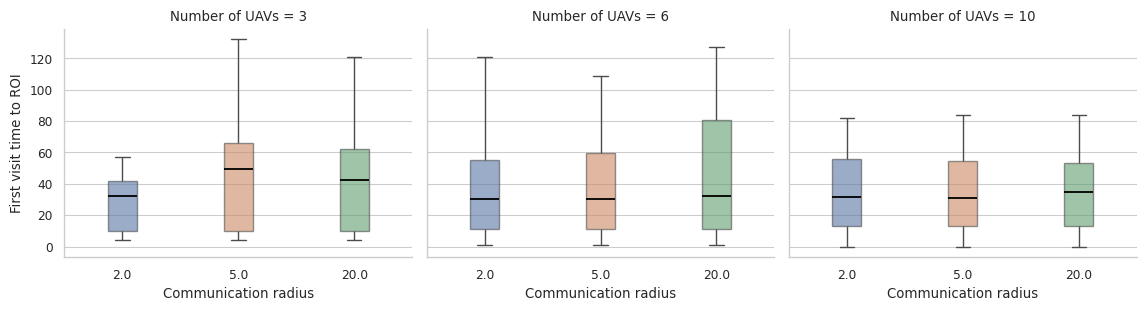

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.0
)

colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"]  # colorblind-safe palette

g = sns.catplot(
    data=roi_df,
    x="comm_radius",
    y="visit_time",
    col="n_agents",
    hue="comm_radius",         
    kind="box",
    showfliers=False,
    height=3.2,
    aspect=1.1,
    width=0.25,
    palette=colors,            
    linewidth=1.0,
    boxprops=dict(alpha=0.6),
    whiskerprops=dict(linewidth=1.0),
    capprops=dict(linewidth=1.0),
    medianprops=dict(color="black", linewidth=1.3)
)

# g.add_legend(title="Comm. radius")

g.set_axis_labels(
    "Communication radius",
    "First visit time to ROI"
)

g._legend.remove()
g.set_titles("Number of UAVs = {col_name}")

# Clean spines
for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()



In [32]:
cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    # label = get_method_label(npz)

    cover_time = npz["cover_time"]
    cover_time = int(cover_time) if cover_time >= 0 else None

    cover_rows.append({
        "map_id": extract_map_id_from_name(run_dir.name),
        "n_agents": npz["n_agents"].item(),
        "comm_radius": npz["comm_radius"].item(),
        "cover_time": cover_time
    })

cover_df = pd.DataFrame(cover_rows)
cover_df

,map_id,n_agents,comm_radius,cover_time
0,v1,3,20.0,278
1,v3,6,5.0,171
2,v3,10,5.0,121
3,v1,3,2.0,392
4,v3,6,2.0,160
5,v3,6,20.0,129
6,v3,10,20.0,59
7,v3,6,5.0,280
8,v1,3,5.0,508
9,v3,10,20.0,128


In [33]:
cover_df["covered"] = cover_df["cover_time"].notna()
cover_df

cover_summary = (
    cover_df
    .groupby(["n_agents", "comm_radius"], as_index=False)
    .agg(
        n_runs=("cover_time", "count"),
        n_covered=("covered", "sum"),
        success_rate=("covered", "mean"),
        mean_cover_time=("cover_time", "mean"),   # ignores NaN by default
        std_cover_time=("cover_time", "std"),
    )
)

cover_summary

,n_agents,comm_radius,n_runs,n_covered,success_rate,mean_cover_time,std_cover_time
0,3,2.0,2,2,1.0,305.500000,122.329473
1,3,5.0,2,2,1.0,405.500000,144.956890
2,3,20.0,2,2,1.0,605.500000,463.154942
3,6,2.0,3,3,1.0,165.000000,9.539392
4,6,5.0,3,3,1.0,268.666667,92.522069
5,6,20.0,3,3,1.0,161.333333,29.263174
6,10,2.0,3,3,1.0,125.333333,14.224392
7,10,5.0,3,3,1.0,154.333333,53.463383
8,10,20.0,3,3,1.0,113.333333,48.686069


In [34]:
final_cover_table = cover_summary.assign(
    cover_time_str=lambda d:
        d["mean_cover_time"].round(1).astype(str)
        + " ± "
        + d["std_cover_time"].round(1).astype(str),
    success_rate_str=lambda d:
        (100 * d["success_rate"]).round(0).astype(int).astype(str) + "%"
)[["n_agents", "comm_radius", "success_rate_str", "cover_time_str"]]

final_cover_table

,n_agents,comm_radius,success_rate_str,cover_time_str
0,3,2.0,100%,305.5 ± 122.3
1,3,5.0,100%,405.5 ± 145.0
2,3,20.0,100%,605.5 ± 463.2
3,6,2.0,100%,165.0 ± 9.5
4,6,5.0,100%,268.7 ± 92.5
5,6,20.0,100%,161.3 ± 29.3
6,10,2.0,100%,125.3 ± 14.2
7,10,5.0,100%,154.3 ± 53.5
8,10,20.0,100%,113.3 ± 48.7


/tmp/ipykernel_81981/684316804.py:3: UserWarning: The palette list has more values (5) than needed (3), which may not be intended.
  g = sns.catplot(


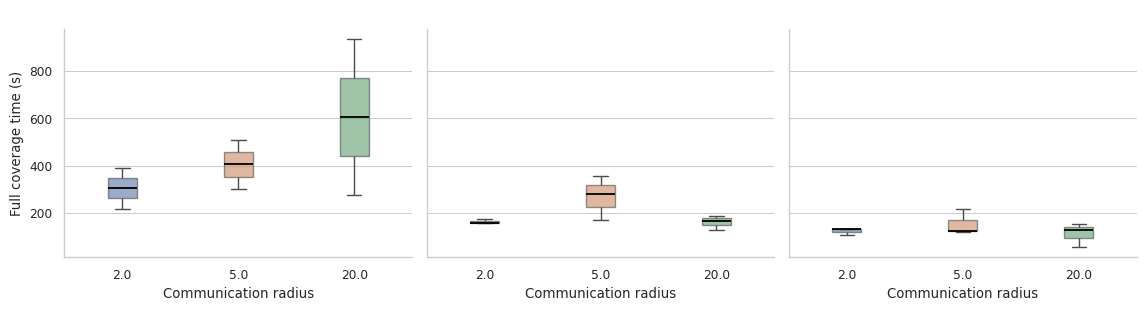

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt
g = sns.catplot(
    data=cover_df,
    x="comm_radius",
    y="cover_time",
    col="n_agents",
    hue="comm_radius",
    kind="box",
    showfliers=False,
    height=3.2,        # match ROI plot
    aspect=1.1,
    width=0.25,
    palette=colors,
    linewidth=1.0,
    boxprops=dict(alpha=0.6),
    whiskerprops=dict(linewidth=1.0),
    capprops=dict(linewidth=1.0),
    medianprops=dict(color="black", linewidth=1.3),
)

g.set_axis_labels("Communication radius", "Full coverage time (s)")
g._legend.remove()
# g.set_titles("UAVs = {col_name}")
g.set_titles(" ")

for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("cover_time.pdf", bbox_inches="tight")



### KL Divergence

In [40]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/AnalysisCommRadius")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpucb_static_3_starts494949_commModelocal_comm_radius20.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_6_starts545454545454_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_10_starts91919191919191919191_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpucb_static_3_starts494949_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_6_starts909090909090_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_6_starts070707070707_commModelocal_comm_radius20.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_10_starts66666666666666666666_commModelocal_comm_radius20.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pu

In [41]:
def kl_divergence(p, q, eps=1e-12):
    p = np.clip(p, eps, None)
    q = np.clip(q, eps, None)
    return np.sum(p * np.log(p / q))

In [42]:
rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = int(npz["n_agents"])
    comm_radius = float(npz["comm_radius"])

    phi_agents_time = npz["phi_agents_time"]   # (T, n_agents, nstates)
    gp_update_steps = npz["gp_update_steps"]   # (n_updates,)

    for t in gp_update_steps:
        phis = phi_agents_time[t]  # (n_agents, nstates)

        # normalize defensively
        phis = phis / phis.sum(axis=1, keepdims=True)

        phi_mean = phis.mean(axis=0)

        kl_vals = [
            kl_divergence(phis[a], phi_mean)
            for a in range(n_agents)
        ]

        rows.append({
            "time": int(t),
            "kl_mean": float(np.mean(kl_vals)),
            "kl_std": float(np.std(kl_vals)),
            "n_agents": n_agents,
            "comm_radius": comm_radius,
            "run": run_dir.name,
        })

kl_df = pd.DataFrame(rows)


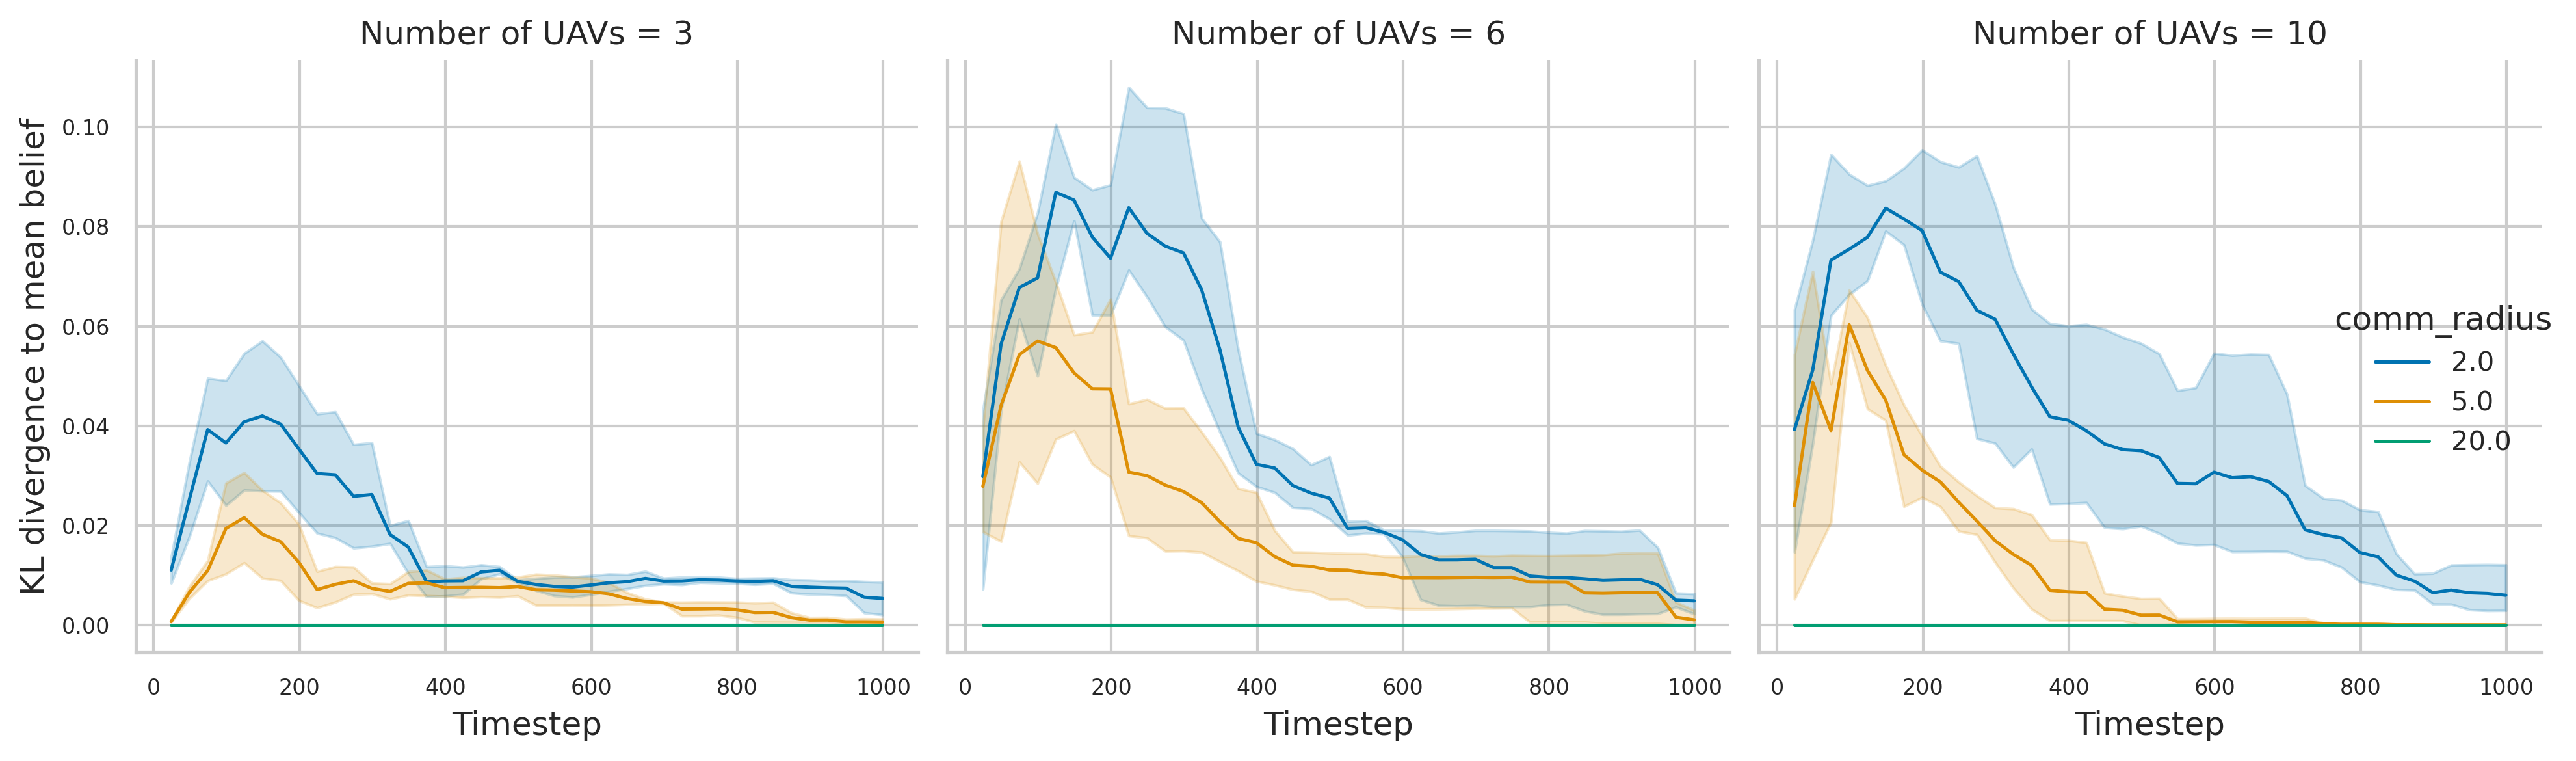

In [58]:
import matplotlib as mpl
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

mpl.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,

    "axes.labelsize": 12,
    "axes.titlesize": 12,

    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    "legend.fontsize": 10,
    "font.size": 10,

    "lines.linewidth": 1.2,
})

g = sns.relplot(
    data=kl_df,
    x="time",
    y="kl_mean",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
    facet_kws=dict(sharey=True, sharex=True),
)

g.set_axis_labels(
    "Timestep",
    "KL divergence to mean belief"
)

g.set_titles("Number of UAVs = {col_name}")

for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()


In [46]:
rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = int(npz["n_agents"])
    comm_radius = float(npz["comm_radius"])
    first_visit = npz["first_visit_step"]  # (nstates,)
    T = int(npz["T"])

    for t in range(T):
        covered = np.sum((first_visit >= 0) & (first_visit <= t))
        frac = covered / len(first_visit)

        rows.append({
            "time": t,
            "coverage": frac,
            "n_agents": n_agents,
            "comm_radius": comm_radius,
            "run": run_dir.name,
        })

cov_df = pd.DataFrame(rows)


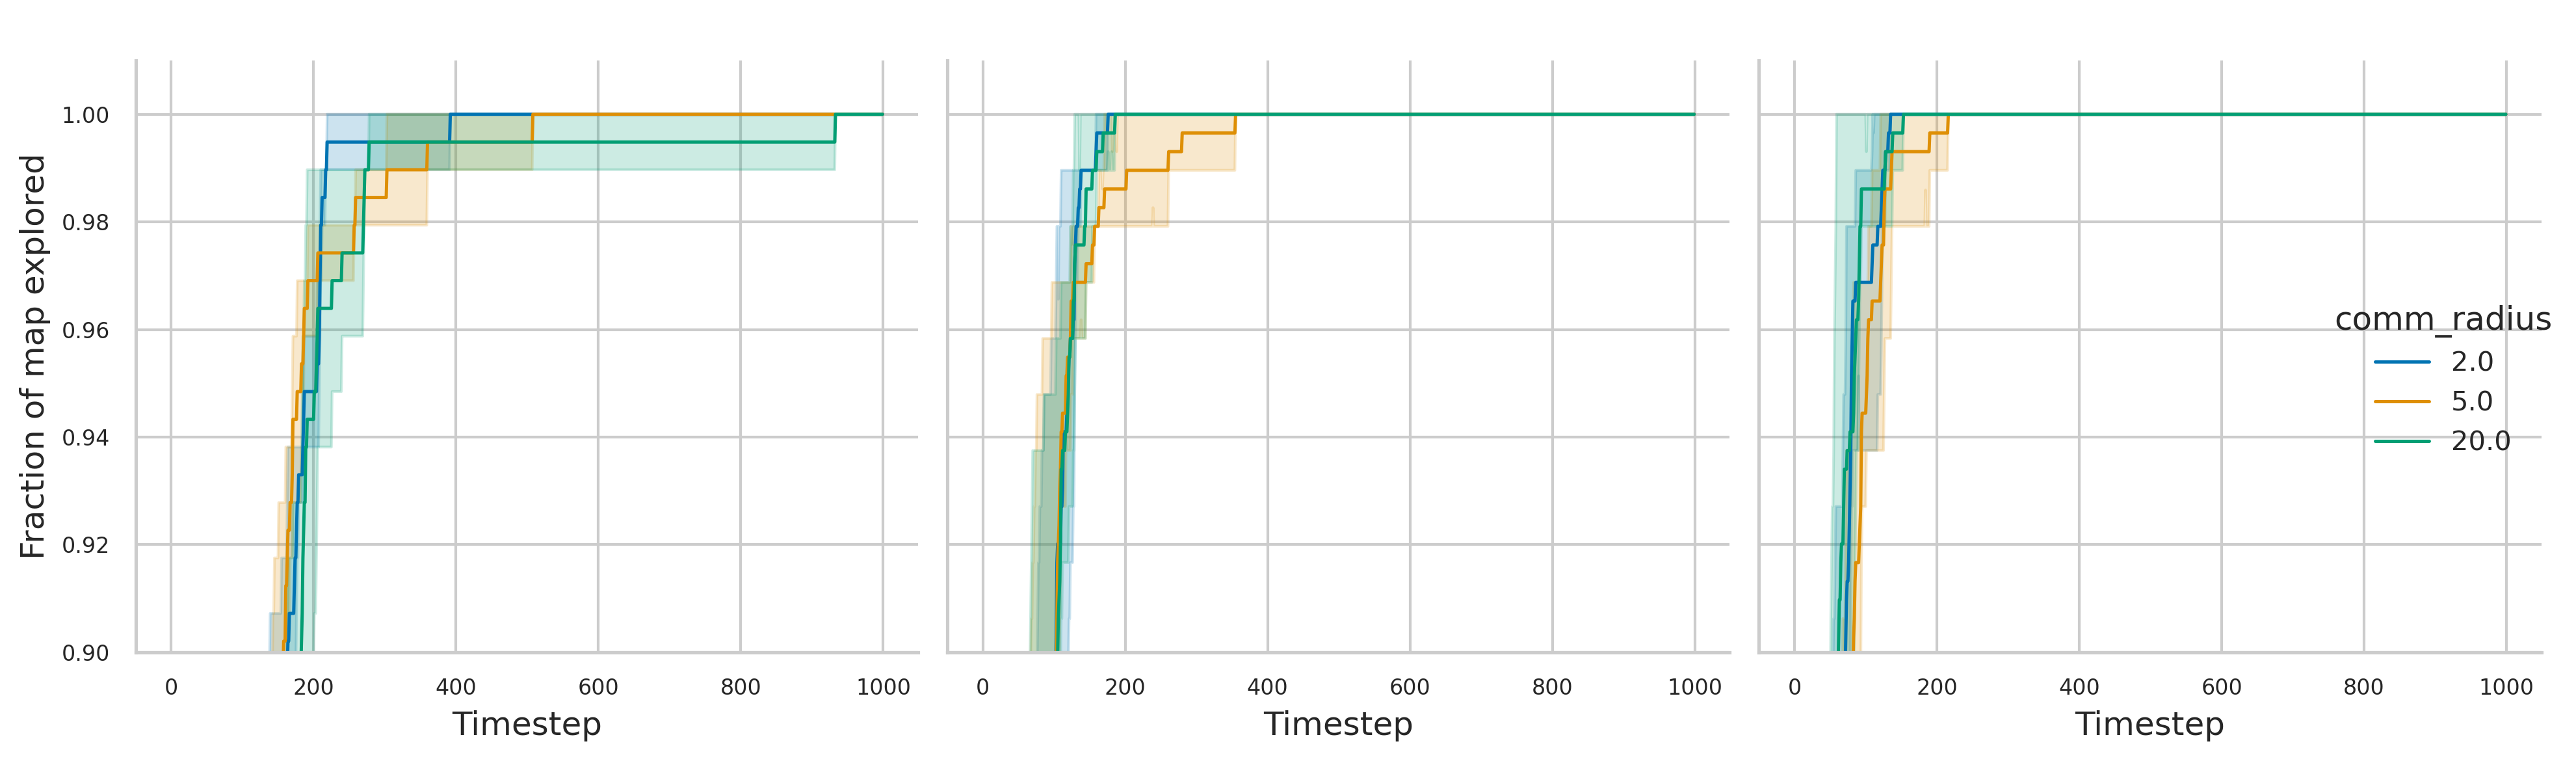

In [59]:
cov_df = pd.DataFrame(rows)
g = sns.relplot(
    data=cov_df,
    x="time",
    y="coverage",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
)


g.set_axis_labels("Timestep", "Fraction of map explored")
# g.set_titles("UAVs = {col_name}")
g.set_titles(" ")

for ax in g.axes.flat:
    ax.set_ylim(0.9, 1.01)   
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("fracKL_.png", bbox_inches="tight")
plt.show()


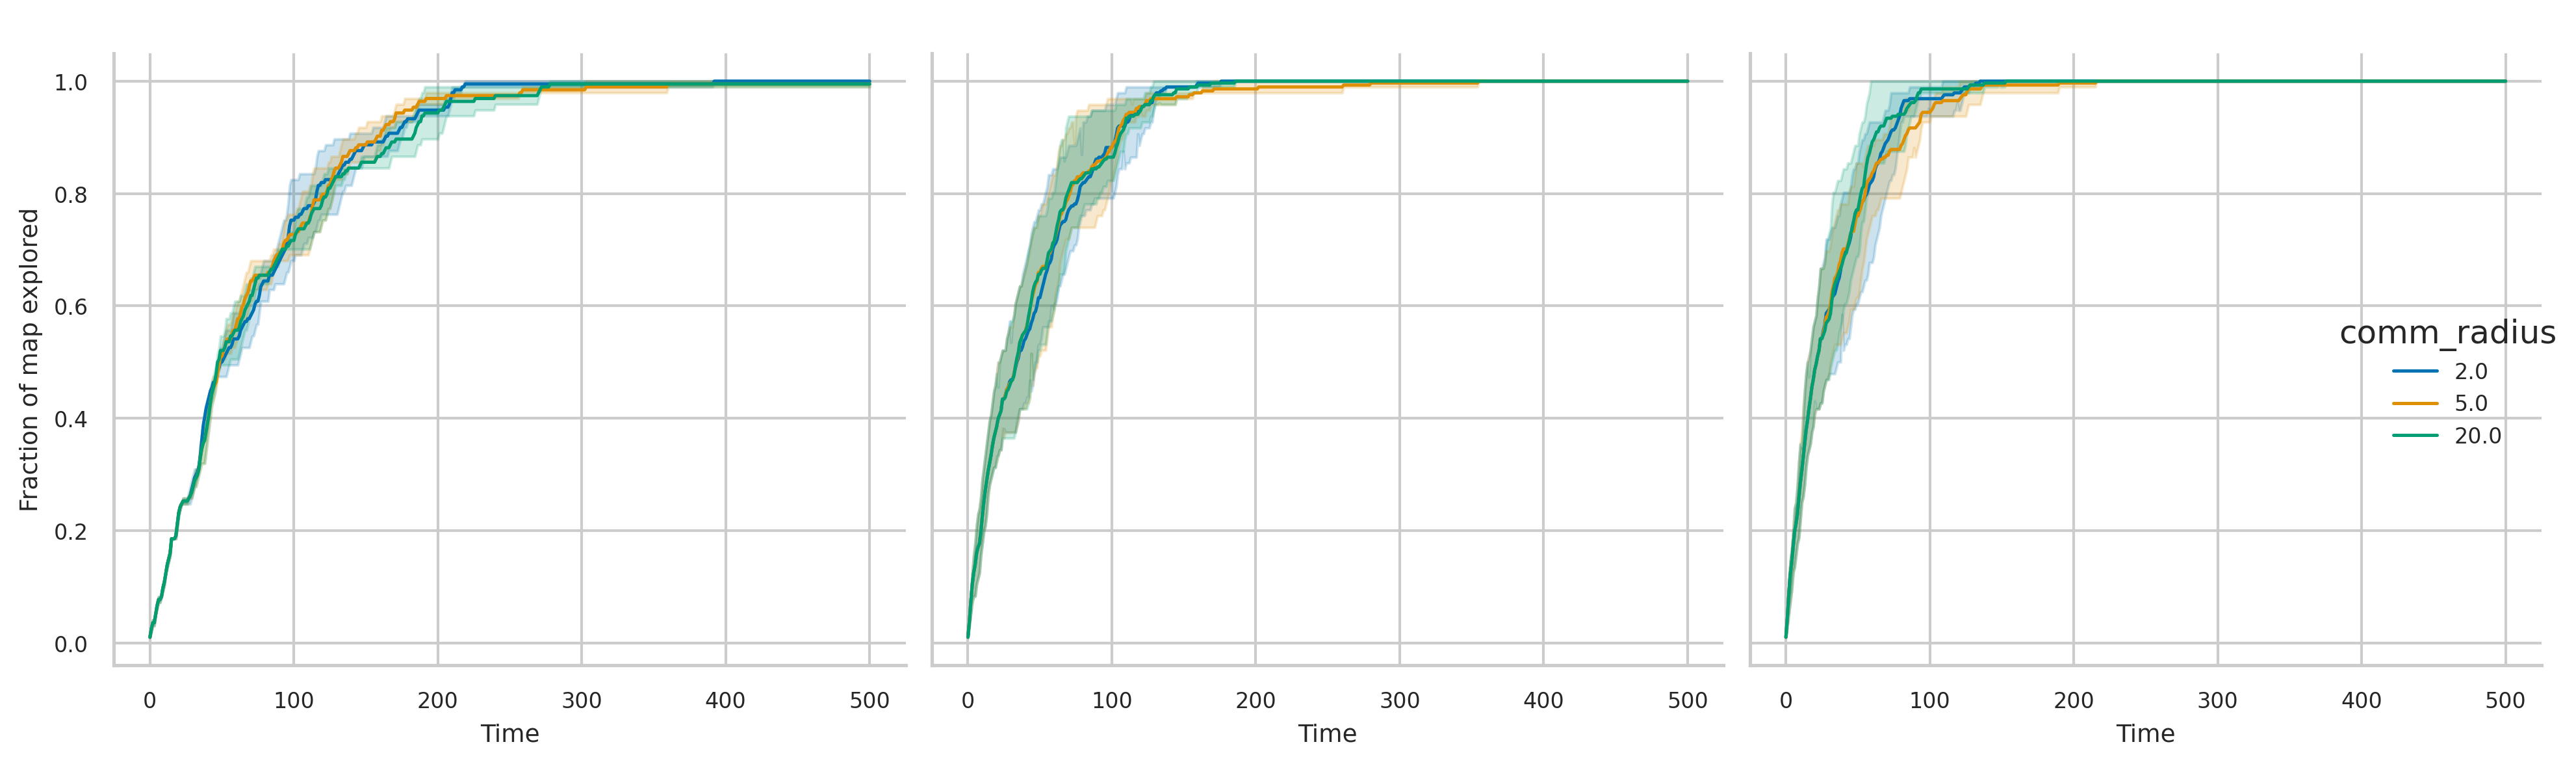

In [ ]:
cov_df_500 = cov_df[cov_df["time"] <= 500]
g = sns.relplot(
    data=cov_df_500,
    x="time",
    y="coverage",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
)

g.set_axis_labels("Time", "Fraction of map explored")
# g.set_titles("Number of UAVs = {col_name}")
g.set_titles(" ")

for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()


### Analysis P Matrix

In [60]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/P_GP_update_dyn")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

T2000_ergodic_GPupdate25_remc_Pupdate25_v1_gpucb_dynamic_1_starts02 → ergodic-remc-ucb
T2000_ergodic_GPupdate25_remc_Pupdate25_v0_gpucb_dynamic_3_starts313131_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T2000_ergodic_GPupdate10_remc_Pupdate10_v1_gpucb_dynamic_3_starts020202_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpucb_dynamic_3_starts313131_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T2000_ergodic_GPupdate50_remc_Pupdate50_v0_gpucb_dynamic_1_starts31 → ergodic-remc-ucb
T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpucb_dynamic_2_starts3131_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T2000_ergodic_GPupdate50_remc_Pupdate50_v1_gpucb_dynamic_3_starts020202_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T2000_ergodic_GPupdate25_remc_Pupdate25_v0_gpucb_dynamic_1_starts31 → ergodic-remc-ucb
T2000_ergodic_GPupdate50_remc_Pupdate50_v0_gpucb_dynamic_3_starts313131_commModel

In [61]:
rows = []


def detect_cfg_starts(true_phi_map_time, atol=1e-12):
    T = true_phi_map_time.shape[0]
    starts = [0]
    for t in range(1, T):
        if not np.allclose(true_phi_map_time[t], true_phi_map_time[t-1], atol=atol):
            starts.append(t)
    return np.array(starts, dtype=int)

debug_rows = []
max_cfg = 0

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    filename = run_dir.name
    gp_u = int(npz["gp_update"])
    p_u  = int(npz["p_update"])

    traj = npz["traj_rc_all"]  # (T_traj, 2)
    true_phi_map_time = npz["true_phi_map_time"]  # (T_phi, nstates)

    cfg_starts = detect_cfg_starts(true_phi_map_time)
    max_cfg = max(max_cfg, len(cfg_starts))

    roi_rc = npz["roi_rc"]
    roi_name = npz["roi_name"]
    n_agents = npz["n_agents"].item()
    start_agents = extract_start_from_name(run_dir.name)

    # build per-ROI-name cell sets (so you can debug per ROI name)
    roi_cells_by_name = {}
    for (r, c), nm in zip(roi_rc, roi_name):
        nm = str(nm)
        roi_cells_by_name.setdefault(nm, set()).add((int(r), int(c)))

    # define cfg intervals (use cfg_starts; end is next start or min length)
    T_end = min(traj.shape[0], true_phi_map_time.shape[0])
    cfg_intervals = []
    for i, t0 in enumerate(cfg_starts):
        t1 = cfg_starts[i+1] if i+1 < len(cfg_starts) else T_end
        t1 = min(t1, T_end)
        cfg_intervals.append((i, int(t0), int(t1)))

    # compute first-visit time per ROI name per cfg interval
    for nm, cellset in roi_cells_by_name.items():
        row = {
            "filename": filename,
            "num agents": n_agents,
            "gp_update": gp_u,
            "p_update": p_u,
            "roi_name": nm,
            "cfg_starts": cfg_starts.copy(),  # keep for debugging (object col)
            "start_agents": start_agents,
        }

        for (cfg_idx, t0, t1) in cfg_intervals:
            visit = np.nan
            # scan only within this cfg interval
            for t in range(t0, t1):
                r, c = traj[t]
                if (int(r), int(c)) in cellset:
                    visit = t
                    break
            row[f"visit_after_cfg{cfg_idx}"] = visit

        debug_rows.append(row)

debug_df = pd.DataFrame(debug_rows)

# make it easier to read: sort & show key columns
visit_cols = [c for c in debug_df.columns if c.startswith("visit_after_cfg")]
show_cols = ["filename", "num agents", "start_agents", "gp_update", "p_update", "roi_name"] + visit_cols

pd.set_option("display.max_rows", None, "display.max_columns", None, "display.width", None)
# display(debug_df[show_cols])
display(debug_df[show_cols].sort_values(["gp_update", "p_update", "filename", "num agents", "start_agents", "roi_name"]).reset_index(drop=True))

,filename,num agents,start_agents,gp_update,p_update,roi_name,visit_after_cfg0,visit_after_cfg1,visit_after_cfg2,visit_after_cfg3
0,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,1,31,10,10,roi1,11,547.0,1128,1579.0
1,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,1,31,10,10,roi2,43,501.0,1001,1500.0
2,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,1,31,10,10,roi3,42,500.0,1001,1500.0
3,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,1,31,10,10,roi4,71,506.0,1000,1513.0
4,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,1,31,10,10,roi5,38,500.0,1001,1500.0
5,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,1,31,10,10,roi6,74,507.0,1056,1512.0
6,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,1,31,10,10,roi7,31,593.0,1086,1559.0
7,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,2,3131,10,10,roi1,54,503.0,1022,1624.0
8,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,2,3131,10,10,roi2,45,569.0,1033,1500.0
9,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,2,3131,10,10,roi3,45,566.0,1033,1500.0


In [62]:

group_cols = ["num agents", "gp_update", "p_update"]
print("cfg_starts:", cfg_starts)

visit_cols = [c for c in debug_df.columns if c.startswith("visit_after_cfg")]

avg_df = (
    debug_df
    .groupby(group_cols, as_index=False)[visit_cols]
    .mean()
    .sort_values(group_cols)
)


# cfg_starts = detect_cfg_starts(true_phi_map_time)

# map column -> cfg index
def cfg_idx_from_col(col):
    return int(col.replace("visit_after_cfg", ""))

avg_delay_df = avg_df.copy()

for col in visit_cols:
    idx = cfg_idx_from_col(col)
    if idx < len(cfg_starts):
        avg_delay_df[col] = avg_delay_df[col] - cfg_starts[idx]


avg_delay_df = avg_delay_df.rename(
    columns={c: f"delay_cfg{cfg_idx_from_col(c)}" for c in visit_cols}
)

display(avg_delay_df)






cfg_starts: [   0  500 1000 1500]


,num agents,gp_update,p_update,delay_cfg0,delay_cfg1,delay_cfg2,delay_cfg3
0,1,10,10,40.923077,46.692308,58.846154,24.000000
1,1,25,25,60.538462,67.307692,77.692308,23.250000
2,1,50,50,46.692308,57.153846,25.846154,65.769231
3,2,10,10,57.769231,66.076923,125.076923,33.230769
4,2,25,25,72.076923,75.846154,38.923077,27.000000
5,2,50,50,56.384615,24.666667,69.076923,30.538462
6,3,10,10,68.692308,93.846154,27.923077,72.000000
7,3,25,25,59.923077,51.000000,59.538462,30.384615
8,3,50,50,54.769231,49.384615,40.307692,72.000000


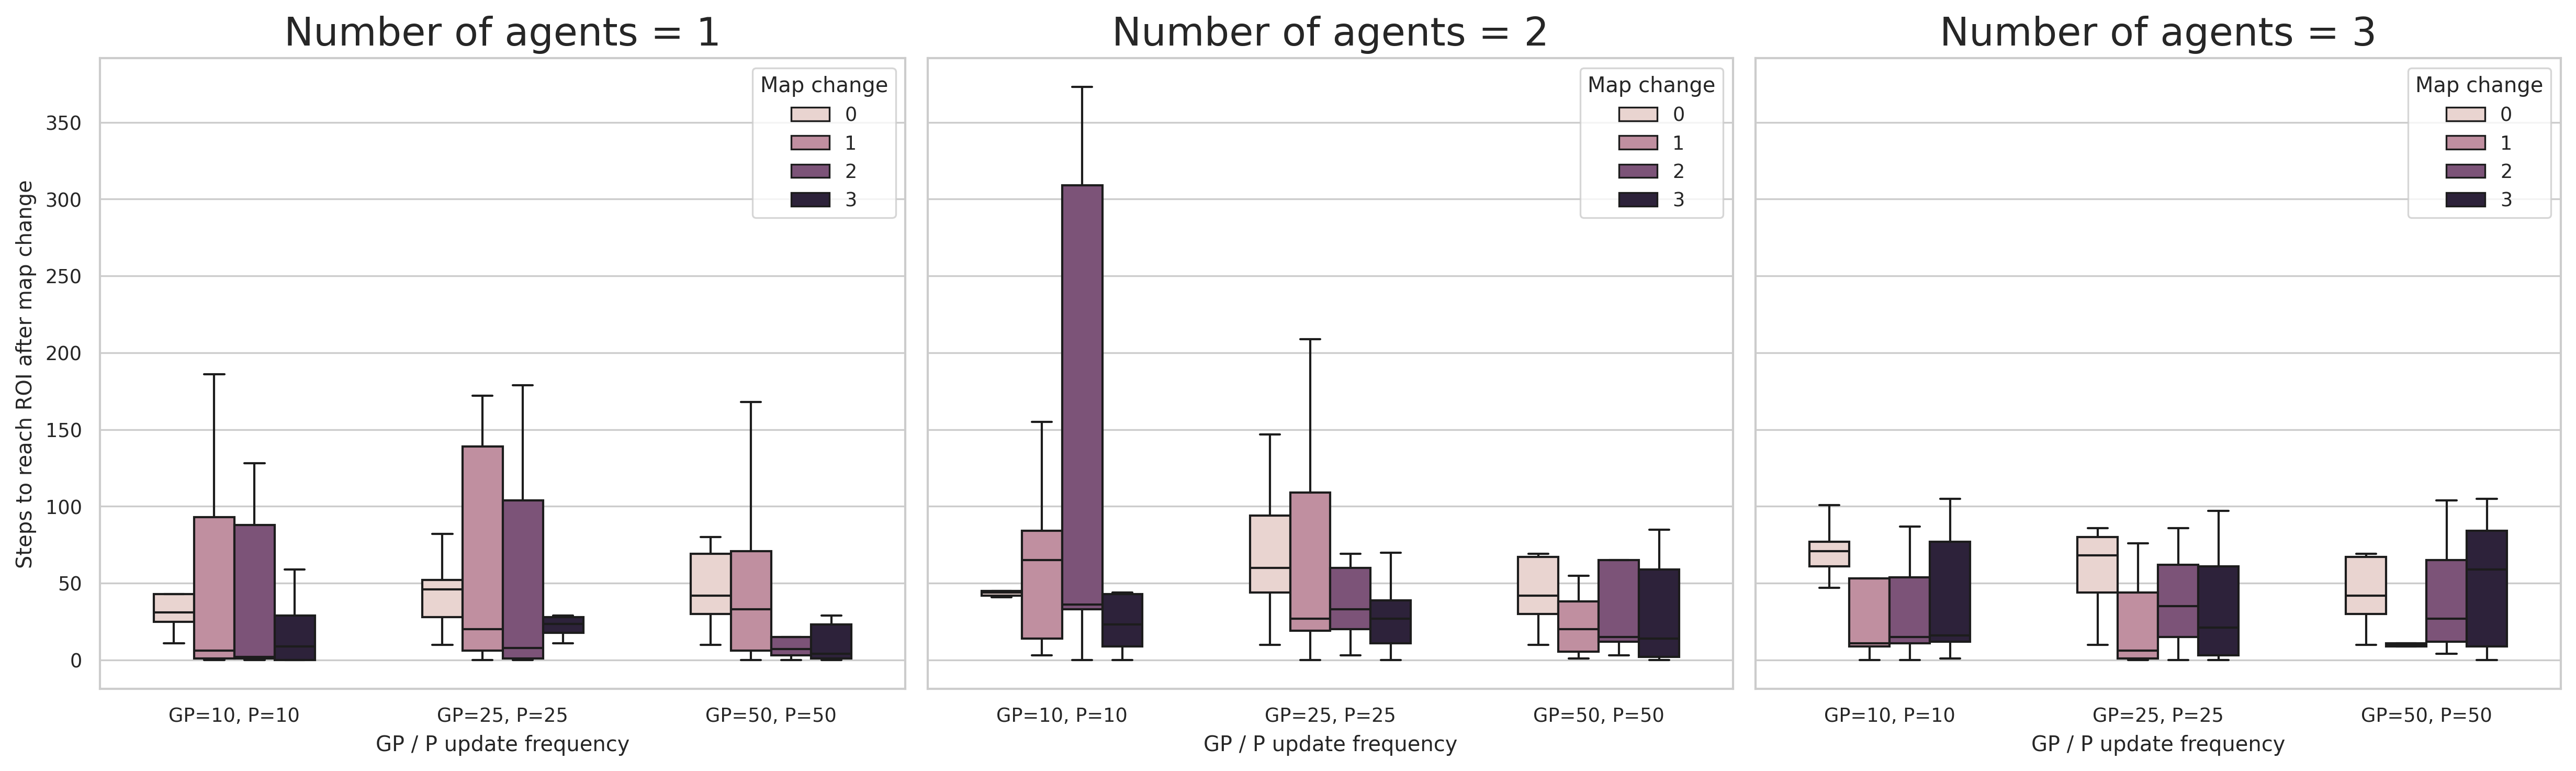

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="paper")

# ---- prepare plotting dataframe ----
delay_cols = [c for c in debug_df.columns if c.startswith("visit_after_cfg")]

plot_df = debug_df.melt(
    id_vars=["num agents", "gp_update", "p_update", "roi_name"],
    value_vars=delay_cols,
    var_name="cfg",
    value_name="visit_time"
)

# extract cfg index ONCE
plot_df["cfg"] = plot_df["cfg"].str.extract(r"cfg(\d+)").astype(int)

# subtract cfg start times
plot_df["delay"] = plot_df["visit_time"] - plot_df["cfg"].map(
    lambda i: cfg_starts[i] if i < len(cfg_starts) else np.nan
)

plot_df = plot_df.dropna(subset=["delay"])

plot_df["update_pair"] = (
    "GP=" + plot_df["gp_update"].astype(str)
    + ", P=" + plot_df["p_update"].astype(str)
)

# ---- plotting: 3 subplots (one per num_agents) ----
agents = sorted(plot_df["num agents"].unique())

fig, axes = plt.subplots(
    1, len(agents),
    figsize=(5.5 * len(agents), 5),
    sharey=True
)

update_order = [
    "GP=10, P=10",
    "GP=25, P=25",
    "GP=50, P=50",
]

if len(agents) == 1:
    axes = [axes]

for ax, n in zip(axes, agents):
    sub = plot_df[plot_df["num agents"] == n]

    sns.boxplot(
        data=sub,
        x="update_pair",
        y="delay",
        hue="cfg",
        order=update_order, 
        showfliers=False,
        width=0.6,
        ax=ax
    )

    ax.set_title(f"Number of agents = {n}", fontsize=18)
    ax.set_xlabel("GP / P update frequency")
    ax.set_ylabel("Steps to reach ROI after map change")

    ax.legend(title="Map change", loc="upper right")

plt.tight_layout()
plt.show()



In [64]:
from collections import defaultdict

cover_times = defaultdict(list)

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = npz["n_agents"].item()
    gp_u = int(npz["gp_update"])
    p_u  = int(npz["p_update"])

    key = (n_agents, gp_u, p_u)

    cover_t = int(npz["cover_time"])
    if cover_t >= 0:
        cover_times[key].append(cover_t)


mean_cover_time = {
    k: np.mean(v) for k, v in cover_times.items() if len(v) > 0
}
print(cover_times.items())

dict_items([((1, 25, 25), [198, 273]), ((3, 25, 25), [41, 84]), ((3, 10, 10), [138, 58]), ((1, 50, 50), [113, 225]), ((2, 10, 10), [82, 208]), ((3, 50, 50), [33, 77]), ((1, 10, 10), [123, 342]), ((2, 50, 50), [54, 120]), ((2, 25, 25), [80, 108])])


In [70]:


curves = defaultdict(lambda: {
    "emp_true": [],
    "bel_true": [],
})

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = npz["n_agents"].item()
    gp_u = int(npz["gp_update"])
    p_u  = int(npz["p_update"])

    key = (n_agents, gp_u, p_u)

    emp_series = npz["emp_series"]
    phi_hat_series = npz["phi_norm_series"]
    true_phi_series = npz["true_phi_map_time"]

    xs, err_emp_true, _, err_bel_true = compute_three_errors_from_series(
        emp_series,
        phi_hat_series,
        true_phi_series,
        stride=1
    )

    curves[key]["emp_true"].append(err_emp_true)
    curves[key]["bel_true"].append(err_bel_true)

In [71]:
update_color_map = {
    (10, 10): "#4C72B0",  # blue
    (25, 25): "#DD8452",  # orange
    (50, 50): "#55A868",  # green
}

update_label_map = {
    (10, 10): "GP=10, P=10",
    (25, 25): "GP=25, P=25",
    (50, 50): "GP=50, P=50",
}


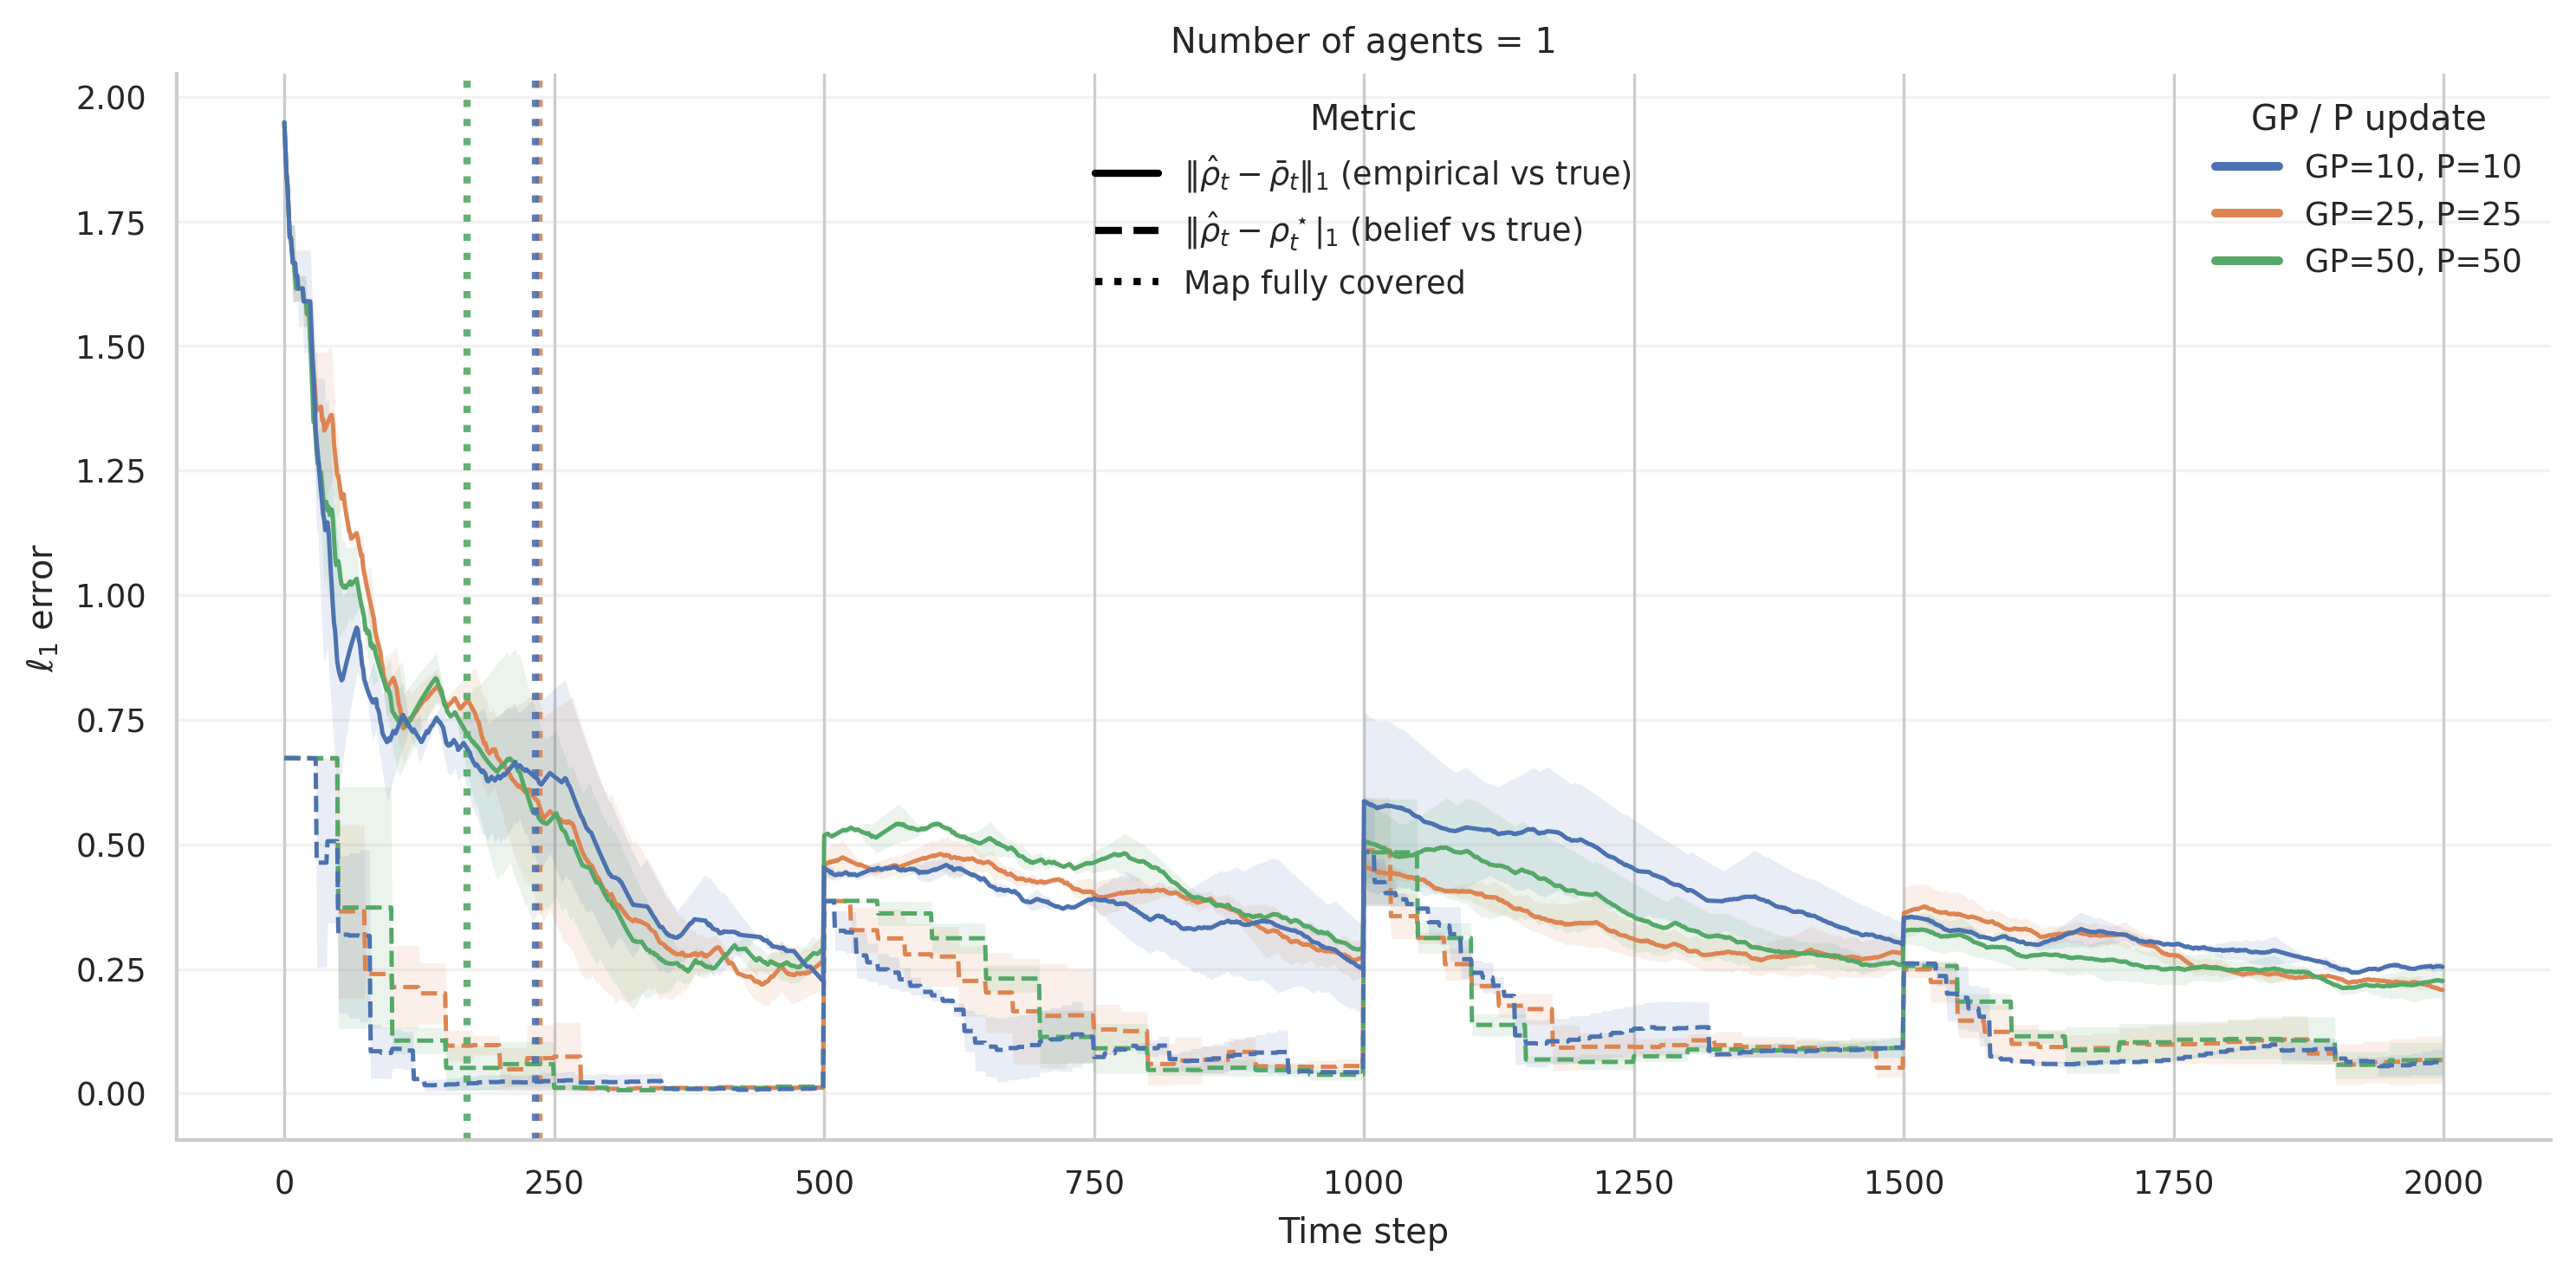

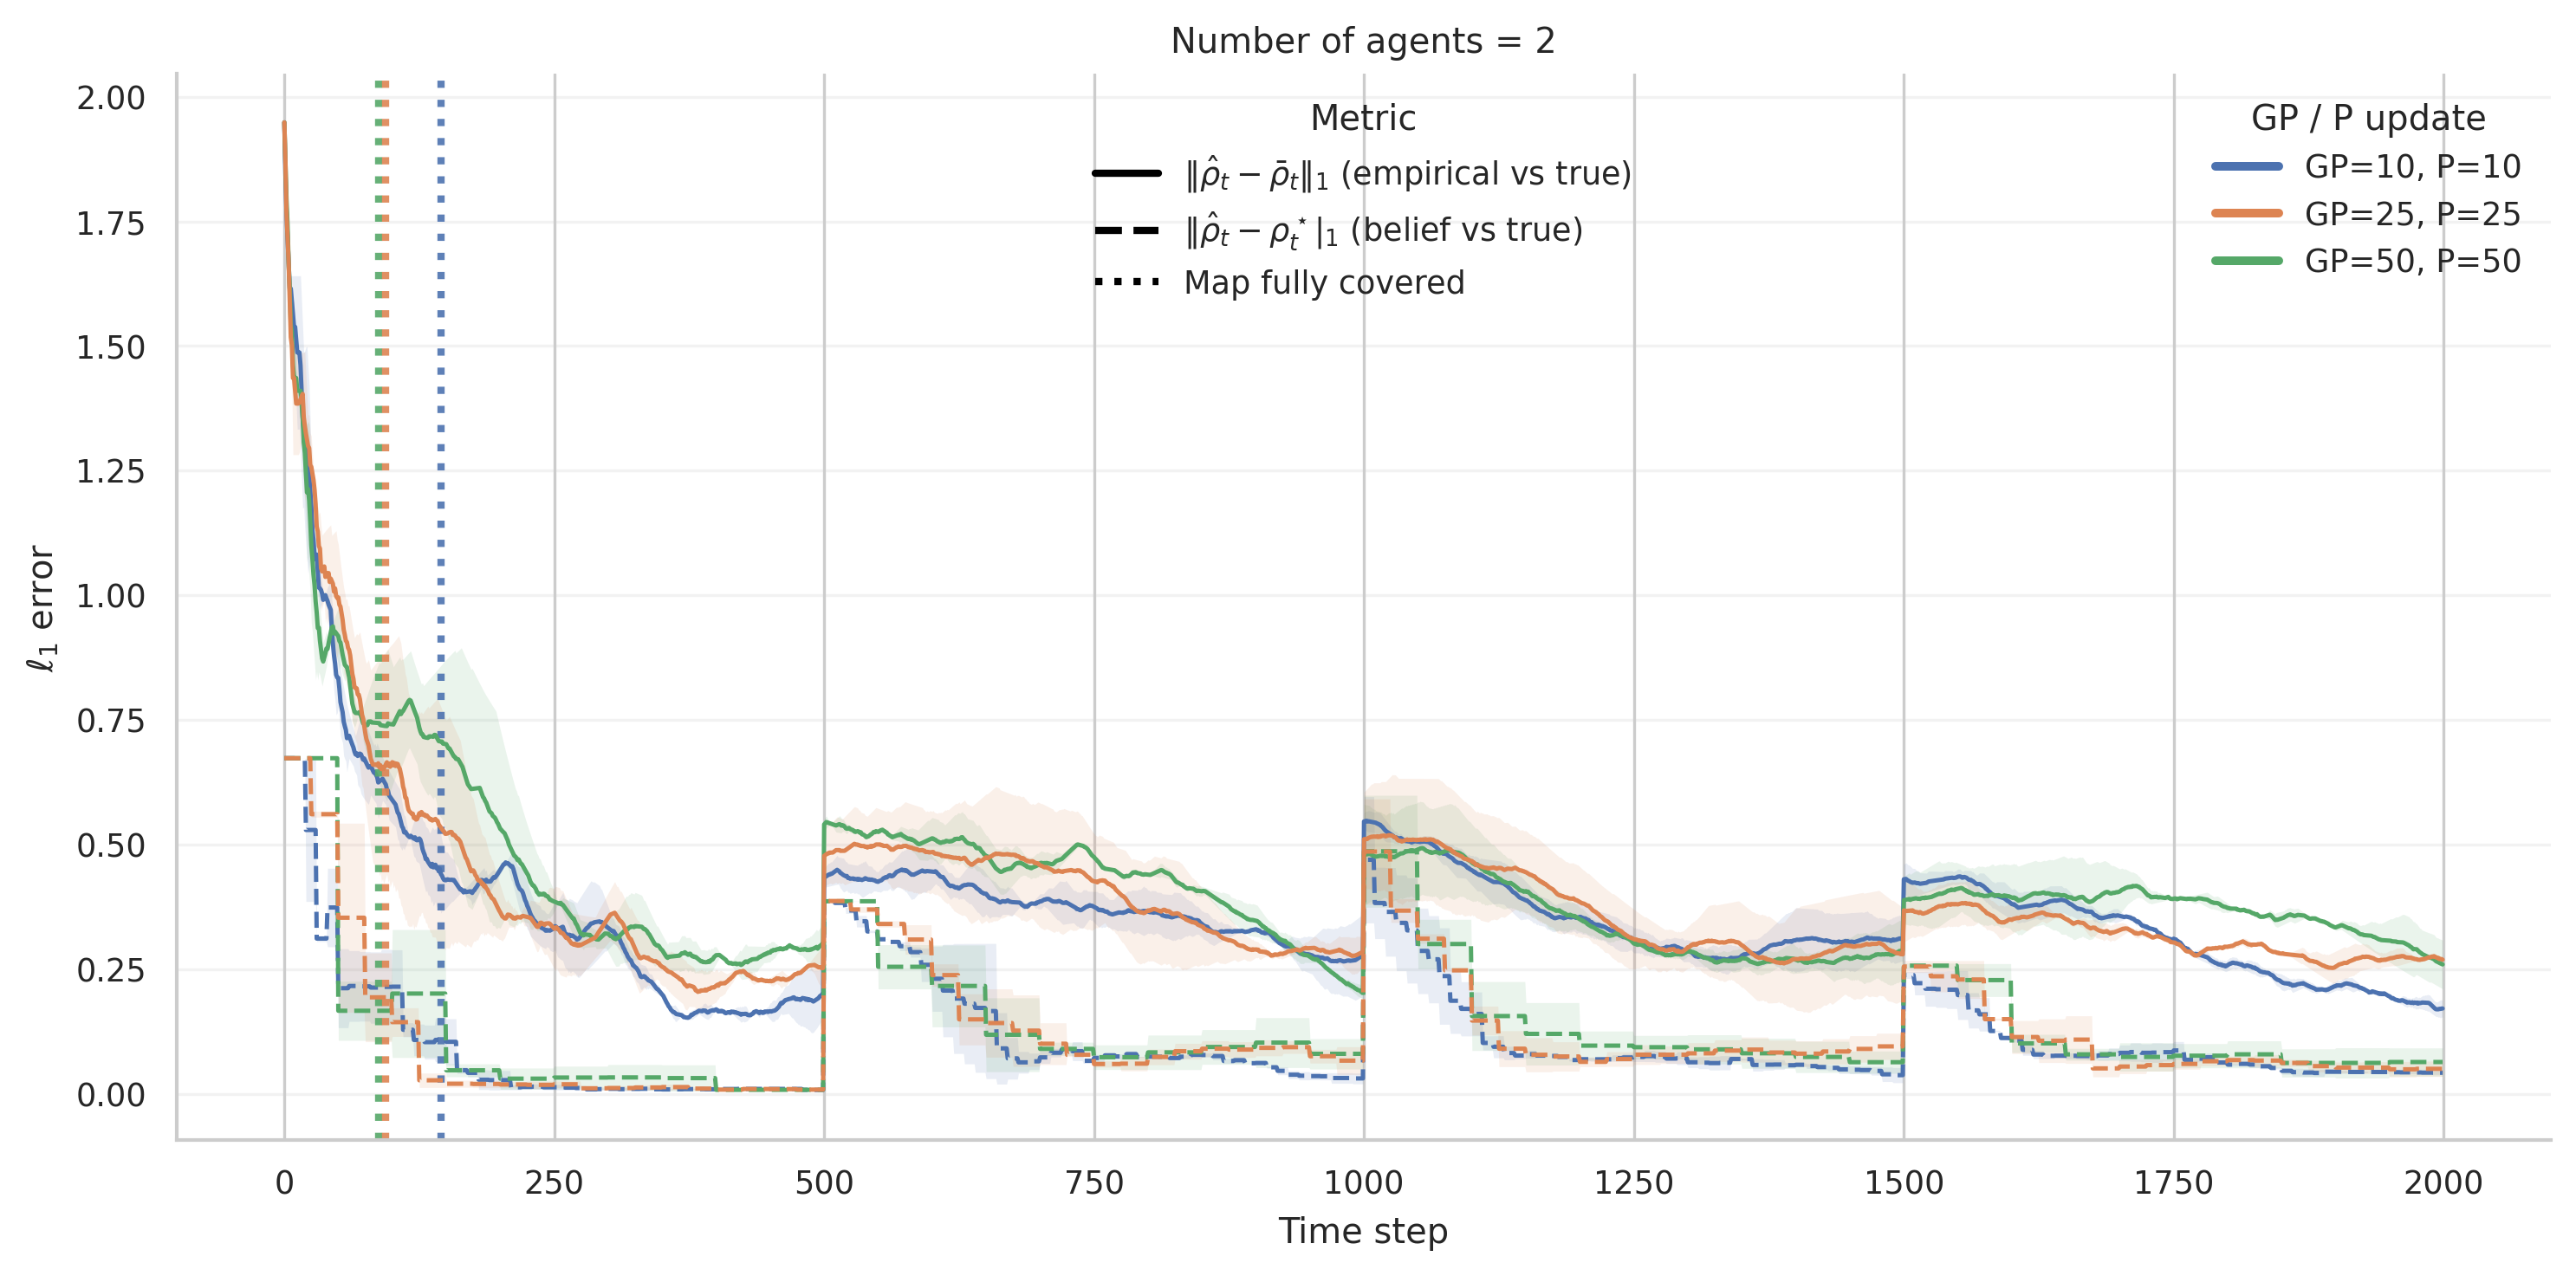

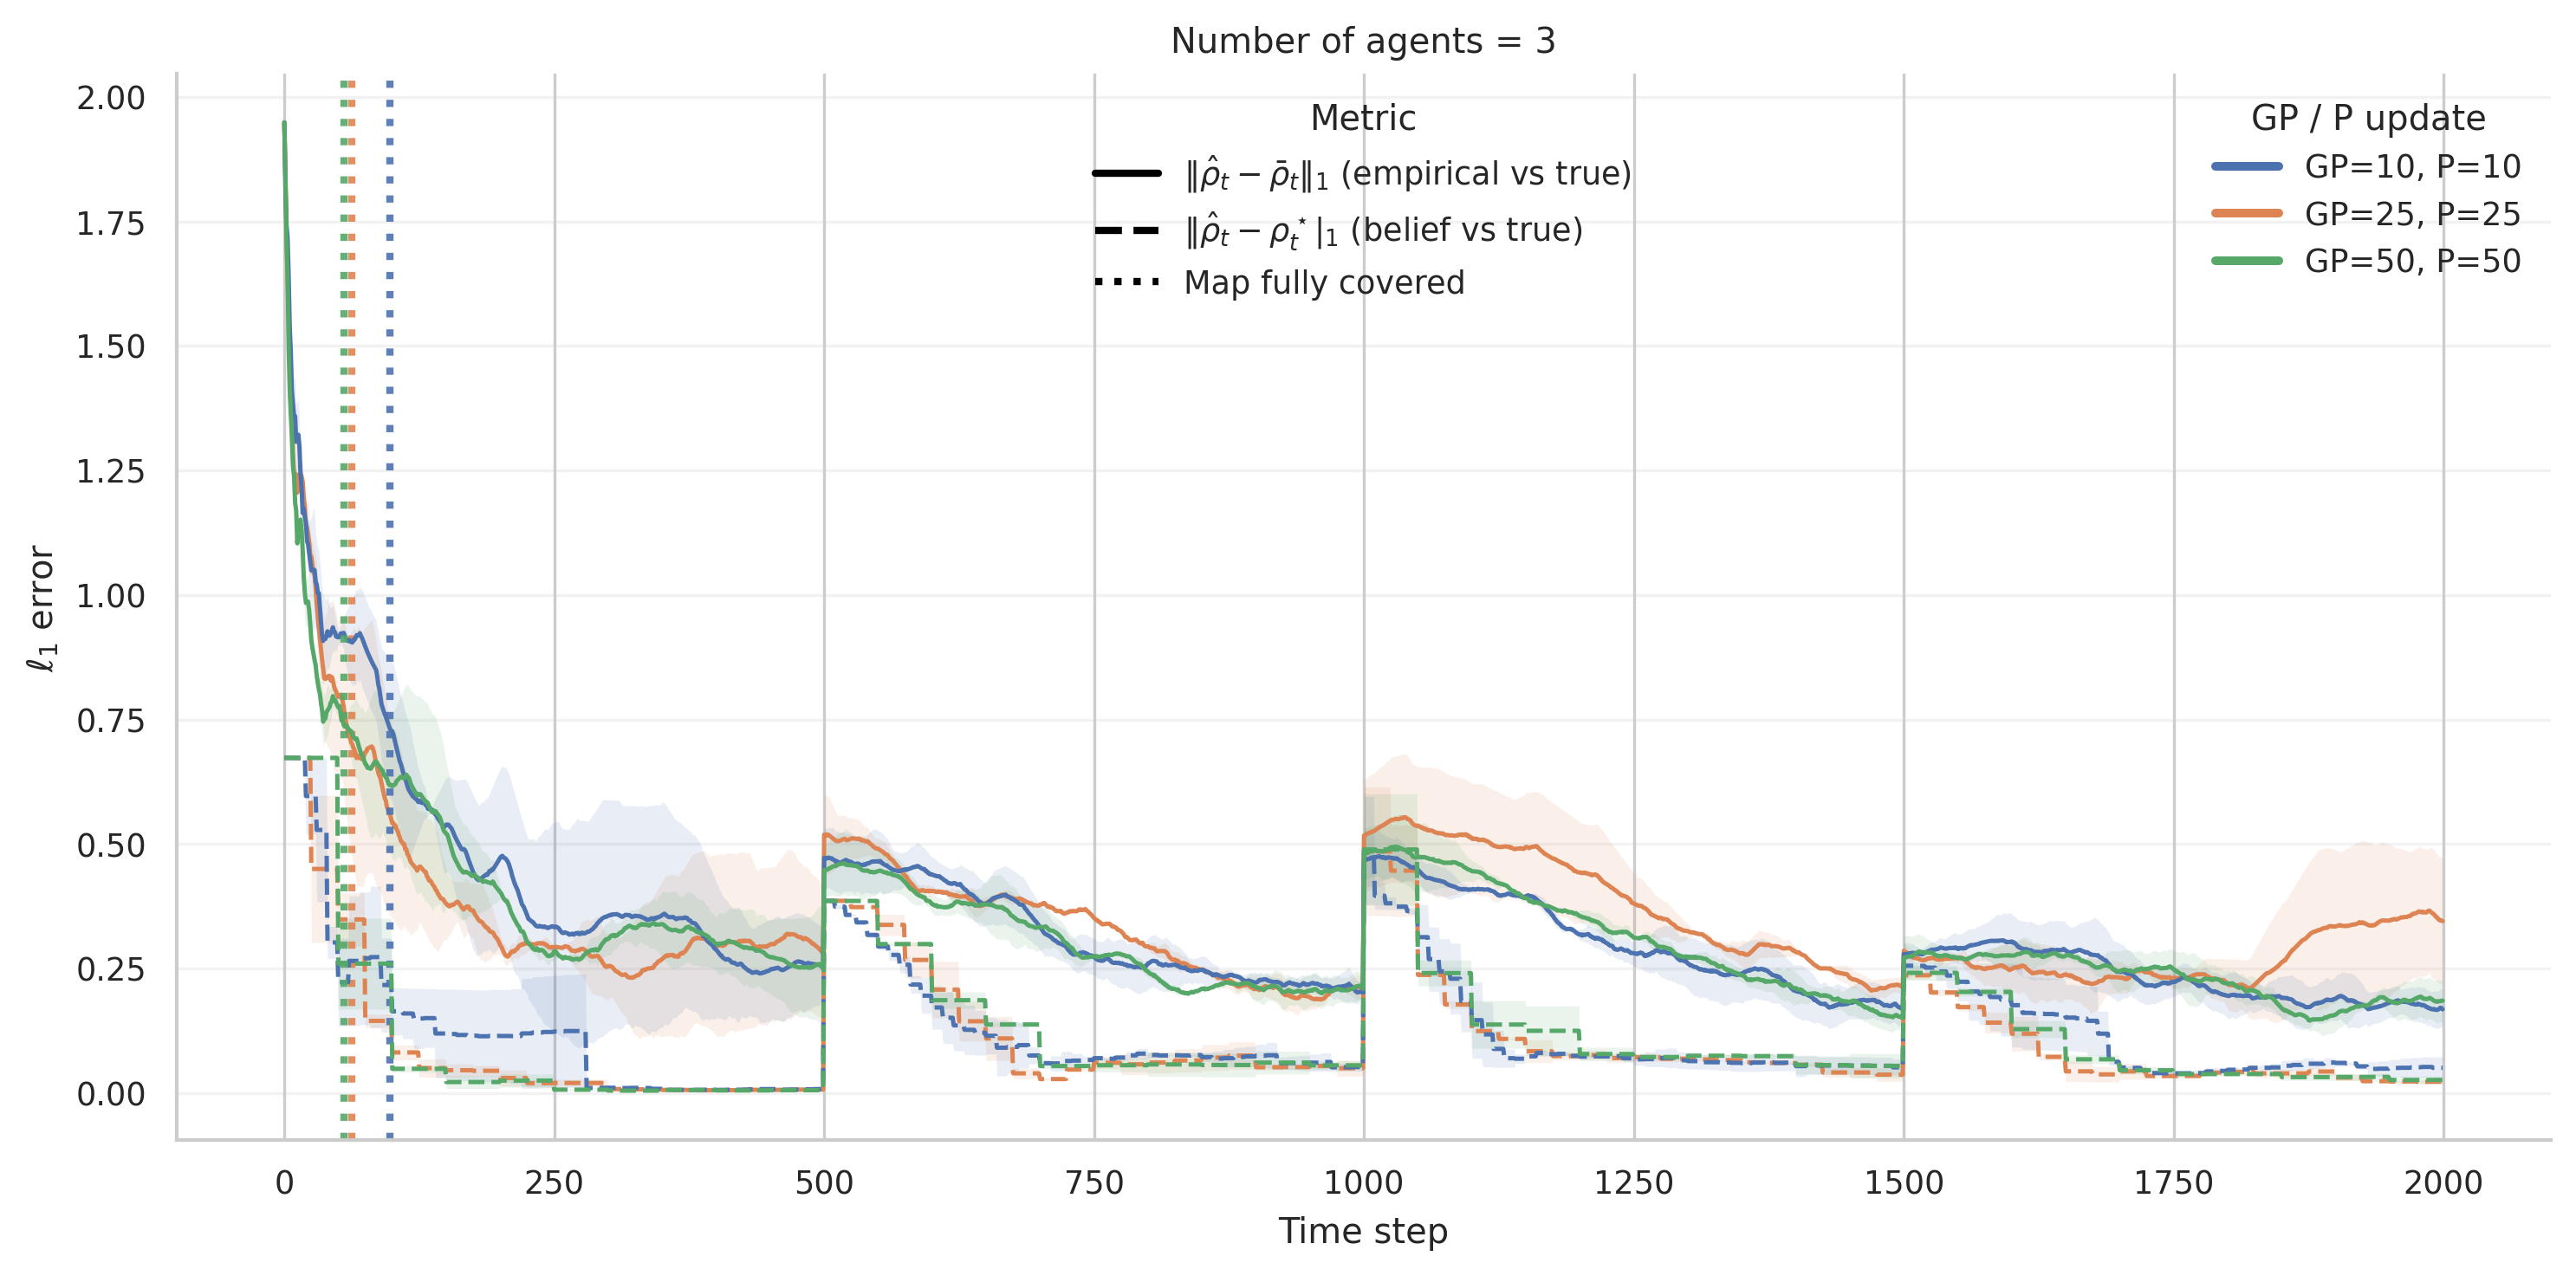

In [72]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np

agents = sorted(set(k[0] for k in curves.keys()))

for n in agents:

    fig, ax = plt.subplots(figsize=(10.0, 5.))

    for (na, gp_u, p_u), data in curves.items():
        if na != n:
            continue

        color = update_color_map[(gp_u, p_u)]
        label = update_label_map[(gp_u, p_u)]

        # ---------- empirical vs true ----------
        Ys = data["emp_true"]
        min_len = min(len(y) for y in Ys)
        Y = np.stack([y[:min_len] for y in Ys])

        mean = Y.mean(axis=0)
        std  = Y.std(axis=0)
        x = np.arange(min_len)

        ax.plot(x, mean, color=color, linestyle="-", label=label)
        ax.fill_between(
            x, mean - std, mean + std,
            color=color, alpha=0.12, linewidth=0
        )

        # ---------- belief vs true ----------
        Ys = data["bel_true"]
        min_len = min(len(y) for y in Ys)
        Y = np.stack([y[:min_len] for y in Ys])

        mean = Y.mean(axis=0)
        std  = Y.std(axis=0)

        ax.plot(x, mean, color=color, linestyle="--")
        ax.fill_between(
            x, mean - std, mean + std,
            color=color, alpha=0.12, linewidth=0
        )

        # ---------- vertical line: map fully covered ----------
        if (n, gp_u, p_u) in mean_cover_time:
            ax.axvline(
                mean_cover_time[(n, gp_u, p_u)],
                color=color,
                linestyle=":",
                linewidth=2.0,
                alpha=0.9
            )

    # ---------- axes & styling ----------
    ax.set_title(f"Number of agents = {n}")
    ax.set_xlabel("Time step")
    ax.set_ylabel(r"$\ell_1$ error")

    ax.grid(True, axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # ---------- legends ----------
    update_handles = [
        Line2D([0], [0], color=update_color_map[(10,10)], lw=2.4, label="GP=10, P=10"),
        Line2D([0], [0], color=update_color_map[(25,25)], lw=2.4, label="GP=25, P=25"),
        Line2D([0], [0], color=update_color_map[(50,50)], lw=2.4, label="GP=50, P=50"),
    ]

    metric_handles = [
        Line2D([0], [0], color="black", lw=2.0, linestyle="-",
               label=r"$\|\hat{\rho}_t - \bar{\rho}_t\|_1$ (empirical vs true)"),
        Line2D([0], [0], color="black", lw=2.0, linestyle="--",
               label=r"$\|\hat{\rho}_t - \rho^\star_t|_1$ (belief vs true)"),
        Line2D([0], [0], color="black", lw=2.0, linestyle=":",
               label="Map fully covered"),
    ]

    leg1 = ax.legend(handles=update_handles, title="GP / P update",
                     loc="upper right", frameon=False)
    leg2 = ax.legend(handles=metric_handles, title="Metric",
                     loc="upper center", frameon=False)
    ax.add_artist(leg1)

    plt.tight_layout()
    plt.show()



In [73]:


cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    cover_rows.append({
        "filename": run_dir.name,
        "num_agents": npz["n_agents"].item(),
        "gp_update": int(npz["gp_update"]),
        "p_update": int(npz["p_update"]),
        "cover_time": int(npz["cover_time"]),
    })

cover_raw_df = pd.DataFrame(cover_rows).sort_values(
    ["num_agents", "gp_update", "p_update", "filename"]
).reset_index(drop=True)

display(cover_raw_df)


,filename,num_agents,gp_update,p_update,cover_time
0,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,1,10,10,342
1,T2000_ergodic_GPupdate10_remc_Pupdate10_v1_gpu...,1,10,10,123
2,T2000_ergodic_GPupdate25_remc_Pupdate25_v0_gpu...,1,25,25,273
3,T2000_ergodic_GPupdate25_remc_Pupdate25_v1_gpu...,1,25,25,198
4,T2000_ergodic_GPupdate50_remc_Pupdate50_v0_gpu...,1,50,50,113
5,T2000_ergodic_GPupdate50_remc_Pupdate50_v1_gpu...,1,50,50,225
6,T2000_ergodic_GPupdate10_remc_Pupdate10_v0_gpu...,2,10,10,82
7,T2000_ergodic_GPupdate10_remc_Pupdate10_v1_gpu...,2,10,10,208
8,T2000_ergodic_GPupdate25_remc_Pupdate25_v0_gpu...,2,25,25,108
9,T2000_ergodic_GPupdate25_remc_Pupdate25_v1_gpu...,2,25,25,80
